# Customer Analytics & Revenue Forecasting

**Goal:** understand what drives revenue and churn for a subscription business, and predict customer revenue with a Linear Regression model.

**Dataset:** 2,560 raw customer records with 15 columns (demographics, plan, usage, marketing channel, churn and revenue). Target variable: `total_revenue`.

**Tools:** Python, pandas, NumPy, matplotlib, scikit-learn

**Steps:** 1. Setup → 2. Data understanding → 3. Data cleaning → 4. Feature engineering → 5. Visual analysis (13 charts) → 6. Linear Regression model (chart 14) → 7. Conclusions

## 1. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folder where all charts are saved
os.makedirs("charts", exist_ok=True)

In [2]:
# Load the dataset 
df = pd.read_csv(r"C:\Users\hp\Desktop\data analyst\project\subscription_data (1).csv")

## 2. Data Understanding
First look at the size, data types and missing values of the raw data.

In [3]:
# Q1. Rows and columns
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (2560, 15)


In [4]:
# Q2. Data types
print("Data types:\n", df.dtypes)

Data types:
 customer_id            int64
age                  float64
gender                   str
city                     str
signup_date              str
last_active_date         str
plan_type                str
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
marketing_channel        str
churned                  str
total_revenue        float64
dtype: object


In [5]:
# Q3. Columns with missing values
missing = df.isnull().sum()
print("Missing values per column:\n", missing)

Missing values per column:
 customer_id            0
age                  105
gender                 0
city                 104
signup_date            0
last_active_date       0
plan_type              0
monthly_fee            0
tenure_months          0
support_tickets        0
avg_session_time     101
discount_percent     105
marketing_channel      0
churned                0
total_revenue          0
dtype: int64


In [6]:
# Q4. Percentage of missing values
print("Missing %:\n", (df.isnull().mean() * 100).round(2)[missing > 0])

Missing %:
 age                 4.10
city                4.06
avg_session_time    3.95
discount_percent    4.10
dtype: float64


**Finding:** 2,560 rows and 15 columns. Four columns have about 4% missing values each: `age`, `city`, `avg_session_time` and `discount_percent`.

## 3. Data Cleaning

### 3.1 Handle missing values
- `age` and `avg_session_time` → median (not affected by extreme values)
- `city` → "Unknown" (a city should not be guessed)
- `discount_percent` → 0 (no recorded discount means no discount)

In [7]:
# Missing age -> median
df["age"] = df["age"].fillna(df["age"].median())

In [8]:
# Missing city -> "Unknown"
df["city"] =  df["city"].fillna("Unknown")

In [9]:
# Missing avg_session_time -> median
df["avg_session_time"] = df["avg_session_time"].fillna(df["avg_session_time"].median())

In [10]:
# Missing discount_percent -> 0
df["discount_percent"] = df["discount_percent"].fillna(0)

# Check: all missing values should now be 0
df.isnull().sum()

customer_id          0
age                  0
gender               0
city                 0
signup_date          0
last_active_date     0
plan_type            0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
marketing_channel    0
churned              0
total_revenue        0
dtype: int64

### 3.2 Remove duplicates

In [11]:
# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 60


In [12]:
# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(2500, 15)


### 3.3 Fix dates and remove illogical records

In [13]:
# Convert date columns to datetime
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["last_active_date"] = pd.to_datetime(df["last_active_date"])
df.dtypes

customer_id                   int64
age                         float64
gender                          str
city                            str
signup_date          datetime64[us]
last_active_date     datetime64[us]
plan_type                       str
monthly_fee                   int64
tenure_months                 int64
support_tickets               int64
avg_session_time            float64
discount_percent            float64
marketing_channel               str
churned                         str
total_revenue               float64
dtype: object

In [14]:
# Find records where last active date is before signup date (illogical)
bad = df["last_active_date"] < df["signup_date"]
print(bad.sum())

# Drop these records
df = df[~bad].reset_index(drop=True)
print(df.shape)

852
(1648, 15)


### 3.4 Check for invalid ages

In [15]:
# Invalid ages (<18 or >80)
invalid_age = (df["age"] < 18) | (df["age"] > 80)
print(invalid_age.sum())
df = df[~invalid_age].reset_index(drop=True)
print(df.shape)

0
(1648, 15)


### 3.5 Save and verify the clean data

In [16]:
# Save the cleaned data
df.to_csv("subscription_clean.csv", index=False)

In [17]:
# Final check: missing values, duplicates, shape
print(df.isnull().sum().sum())
print(df.duplicated().sum())
print(df.shape)

0
0
(1648, 15)


**Cleaning summary:** filled all missing values, removed 60 duplicate rows, converted dates to datetime, and dropped 852 records where last active date was before signup date. No invalid ages were found (ages range from 18 to 64). The clean dataset has **1,648 rows**.

## 4. Feature Engineering
Created 14 new features: tenure in years, revenue per month, churn flag, age group, high-value flag, days active, session category, discount category, signup month, signup year, support intensity, revenue category, plan rank and engagement score.

In [18]:
# Customer tenure in years (months divided by 12)
df["customer_tenure_years"] = df["tenure_months"] / 12

In [19]:
#  Average revenue earned per month of tenure
df["revenue_per_month"] = df["total_revenue"] / df["tenure_months"]

In [20]:
# Binary churn flag: 1 if churned is "Yes", otherwise 0
df["churn_flag"] = (df["churned"] == "Yes").astype(int)

In [21]:
# Age group: under 25 = Young, under 45 = Middle, otherwise Senior
df["age_group"] = np.where(df["age"] < 25, "Young",
                  np.where(df["age"] < 45, "Middle", "Senior"))

In [22]:
# High-value customer: revenue above the median revenue = Yes
median_rev = df["total_revenue"].median()
df["high_value_customer"] = np.where(df["total_revenue"] > median_rev, "Yes", "No")

In [23]:
# Days active: last active date minus signup date, as a number of days
df["days_active"] = (df["last_active_date"] - df["signup_date"]).dt.days

In [24]:
# Session usage category based on average session time
df["session_category"] = np.where(df["avg_session_time"] < 30, "Low",
                         np.where(df["avg_session_time"] < 60, "Medium", "High"))

In [25]:
# Discount category: 0 = No Discount, up to 10 = Low, above 10 = High
df["discount_category"] = np.where(df["discount_percent"] == 0, "No Discount",
                          np.where(df["discount_percent"] <= 10, "Low Discount", "High Discount"))

In [26]:
# Month the customer signed up (1-12)
df["signup_month"] = df["signup_date"].dt.month

In [27]:
# Year the customer signed up
df["signup_year"] = df["signup_date"].dt.year

In [28]:
# Support intensity: 5 or more tickets = High, otherwise Low
df["support_intensity"] = np.where(df["support_tickets"] >= 5, "High", "Low")

In [29]:
# Revenue category: under 10000 = Low, under 30000 = Medium, otherwise High
df["revenue_category"] = np.where(df["total_revenue"] < 10000, "Low",
                         np.where(df["total_revenue"] < 30000, "Medium", "High"))

In [30]:
# Plan rank for modeling: Basic = 1, Standard = 2, Premium = 3
df["plan_rank"] = df["plan_type"].map({"Basic": 1, "Standard": 2, "Premium": 3})

In [31]:
# 14. Engagement score: more session time and fewer tickets = higher score
#     (+1 avoids division by zero when a customer has no tickets)
df["engagement_score"] = df["avg_session_time"] / (df["support_tickets"] + 1)

In [32]:
# Check the new features
print("Shape:", df.shape)    
print("Missing plan_rank:", df["plan_rank"].isnull().sum())  
print("Min days_active:", df["days_active"].min())  
print(df[["customer_tenure_years", "revenue_per_month", "churn_flag",
          "age_group", "high_value_customer", "engagement_score"]].head())

Shape: (1648, 29)
Missing plan_rank: 0
Min days_active: 0
   customer_tenure_years  revenue_per_month  churn_flag age_group  \
0               2.083333        1206.716000           1    Senior   
1               1.833333        1256.472727           1    Senior   
2               0.333333         773.212500           0    Middle   
3               0.166667         417.175000           0    Middle   
4               1.750000         661.242857           0    Middle   

  high_value_customer  engagement_score  
0                 Yes             2.625  
1                 Yes            18.580  
2                  No            41.930  
3                  No            53.990  
4                 Yes            11.310  


In [33]:
# Save the dataset with the new features
df.to_csv("subscription_features.csv", index=False)

## 5. Visual Analysis

### A. Data understanding and distributions

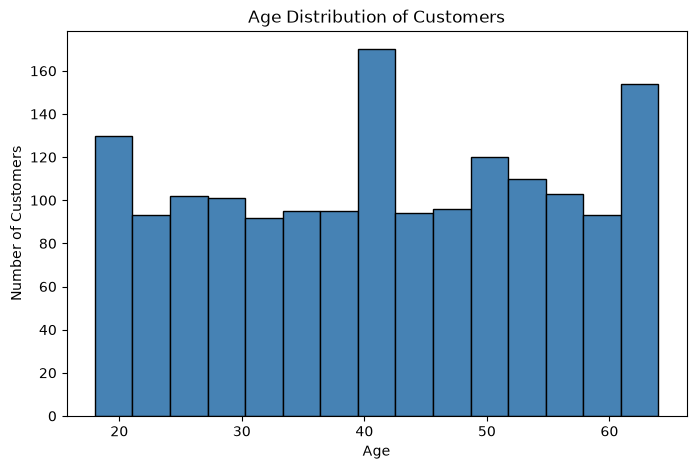

In [34]:
# Age distribution (histogram)
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=15, color="steelblue", edgecolor="black")  # bins = number of bars
plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.savefig("charts/01_age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** customers are aged 18 to 64 and spread fairly evenly across the range, with no strong skew.

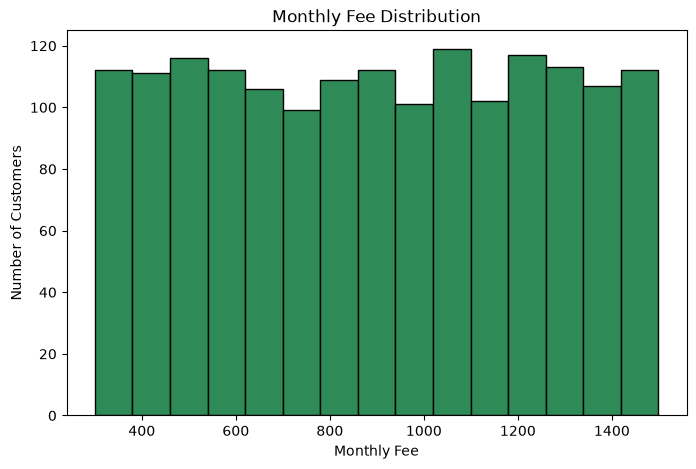

In [35]:
# Monthly fee distribution (histogram)
plt.figure(figsize=(8, 5))
plt.hist(df["monthly_fee"], bins=15, color="seagreen", edgecolor="black")
plt.title("Monthly Fee Distribution")
plt.xlabel("Monthly Fee")
plt.ylabel("Number of Customers")
plt.savefig("charts/02_monthly_fee_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** monthly fees vary widely across customers and the distribution is fairly symmetric.

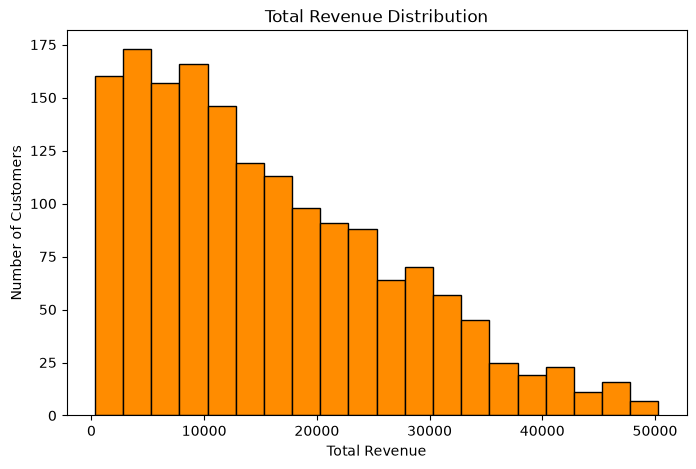

In [36]:
# Total revenue distribution (histogram)
plt.figure(figsize=(8, 5))
plt.hist(df["total_revenue"], bins=20, color="darkorange", edgecolor="black")
plt.title("Total Revenue Distribution")
plt.xlabel("Total Revenue")
plt.ylabel("Number of Customers")
plt.savefig("charts/03_total_revenue_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** revenue is right-skewed. Most customers generate low to medium revenue, while a small group generates very high revenue.

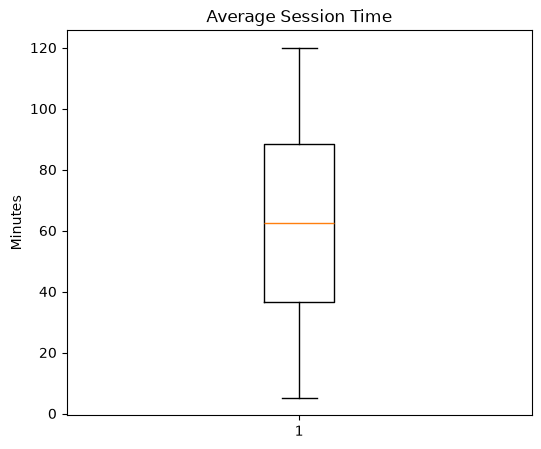

In [37]:
# Average session time (boxplot)
plt.figure(figsize=(6, 5))
plt.boxplot(df["avg_session_time"])
plt.title("Average Session Time")
plt.ylabel("Minutes")
plt.savefig("charts/04_session_time_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** median session time is about 62 minutes, the middle 50% of customers sit between roughly 37 and 88 minutes, and there are no outliers.

### B. Categorical insights

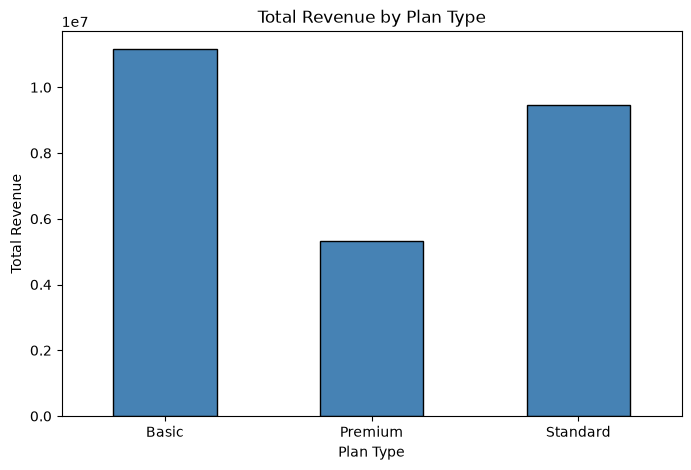

In [38]:
# Revenue by plan type (bar chart)
plan_revenue = df.groupby("plan_type")["total_revenue"].sum()

plt.figure(figsize=(8, 5))
plan_revenue.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Total Revenue by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.savefig("charts/05_revenue_by_plan.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Basic brings the most total revenue (about 11.2M), then Standard (9.5M) and Premium (5.3M). This is because Basic has the most customers. Average revenue per customer is similar across plans (about 15.5K to 16.1K).

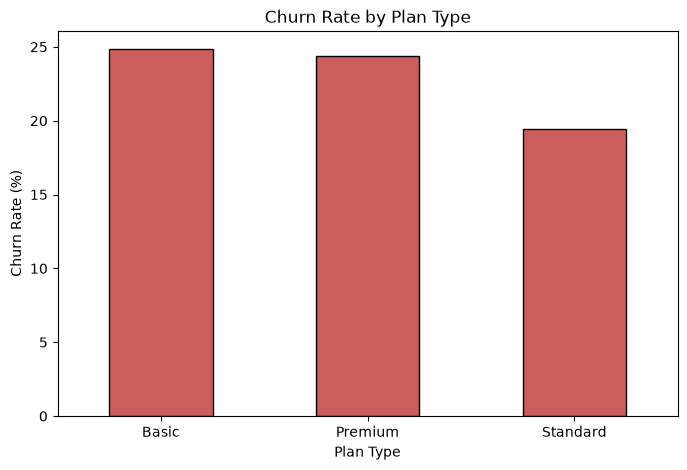

In [39]:
# Churn rate by plan type (bar chart)
churn_rate = df.groupby("plan_type")["churn_flag"].mean() * 100

plt.figure(figsize=(8, 5))
churn_rate.plot(kind="bar", color="indianred", edgecolor="black")
plt.title("Churn Rate by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.savefig("charts/06_churn_by_plan.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Standard has the lowest churn (about 19.4%). Basic (24.8%) and Premium (24.4%) churn more.

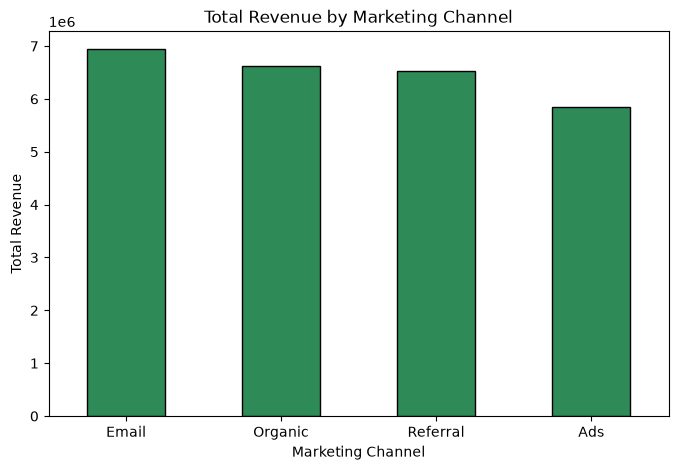

In [40]:
# Revenue by marketing channel (bar chart)
channel_revenue = df.groupby("marketing_channel")["total_revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
channel_revenue.plot(kind="bar", color="seagreen", edgecolor="black")
plt.title("Total Revenue by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.savefig("charts/07_revenue_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Email is the best acquisition channel (about 6.9M), followed closely by Organic and Referral. Ads is the lowest (about 5.8M).

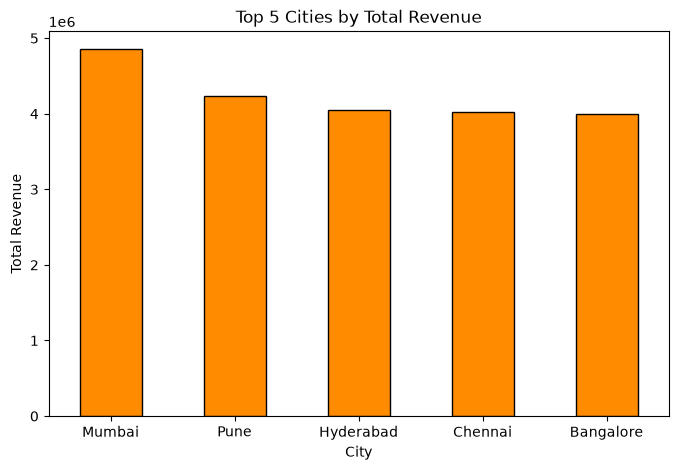

In [41]:
# Revenue by city, top 5 (bar chart)
city_revenue = (df[df["city"] != "Unknown"]
                .groupby("city")["total_revenue"].sum()
                .sort_values(ascending=False)
                .head(5))

plt.figure(figsize=(8, 5))
city_revenue.plot(kind="bar", color="darkorange", edgecolor="black")
plt.title("Top 5 Cities by Total Revenue")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.savefig("charts/08_top5_cities.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Mumbai, Pune and Hyderabad lead in revenue, but the gaps between the top cities are small.

### C. Behavioral and time-based trends

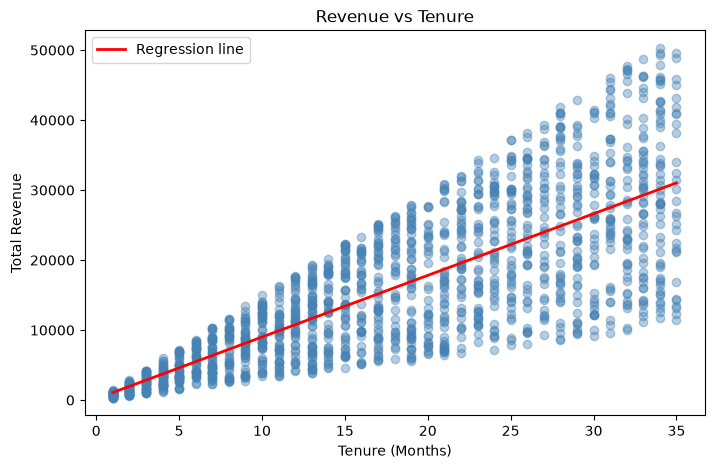

In [42]:
# Revenue vs tenure (scatter + regression line)
plt.figure(figsize=(8, 5))
plt.scatter(df["tenure_months"], df["total_revenue"], alpha=0.4, color="steelblue")

# Fit a straight line: slope (m) and intercept (b)
m, b = np.polyfit(df["tenure_months"], df["total_revenue"], 1)
x = np.sort(df["tenure_months"])
plt.plot(x, m * x + b, color="red", linewidth=2, label="Regression line")

plt.title("Revenue vs Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Revenue")
plt.legend()
plt.savefig("charts/09_revenue_vs_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** revenue rises steadily with tenure (correlation about 0.78). Each extra month adds roughly 880 in revenue, so customer loyalty pays off.

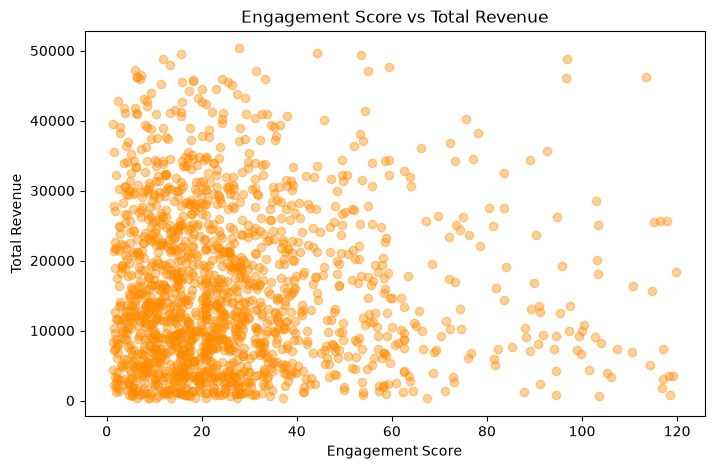

In [43]:
# Engagement score vs revenue (scatter)
plt.figure(figsize=(8, 5))
plt.scatter(df["engagement_score"], df["total_revenue"], alpha=0.4, color="darkorange")
plt.title("Engagement Score vs Total Revenue")
plt.xlabel("Engagement Score")
plt.ylabel("Total Revenue")
plt.savefig("charts/10_engagement_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** there is no visible pattern (correlation close to 0). Engagement score does not translate into higher revenue in this data.

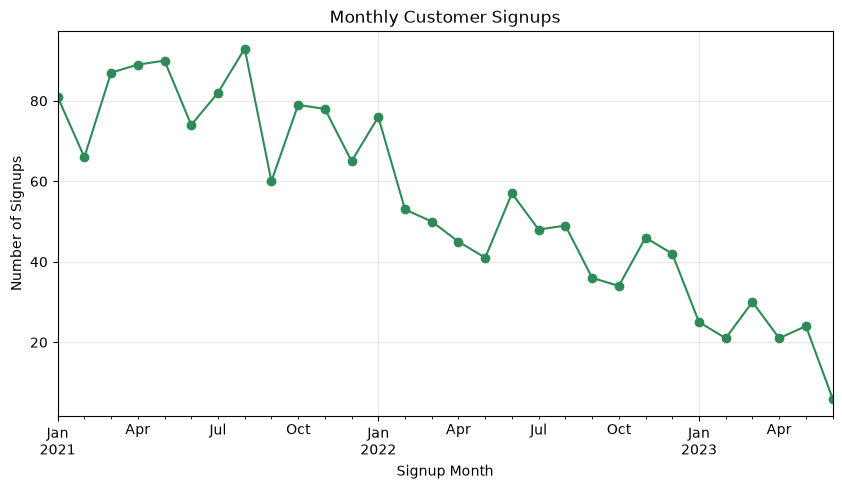

In [44]:
# Signup trend over time (line chart)
signups = df.groupby(df["signup_date"].dt.to_period("M")).size()

plt.figure(figsize=(10, 5))
signups.plot(kind="line", marker="o", color="seagreen")
plt.title("Monthly Customer Signups")
plt.xlabel("Signup Month")
plt.ylabel("Number of Signups")
plt.grid(alpha=0.3)
plt.savefig("charts/11_signup_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** signups cover 30 months, from January 2021 to June 2023. The last month looks low only because the data ends on 15 June 2023.

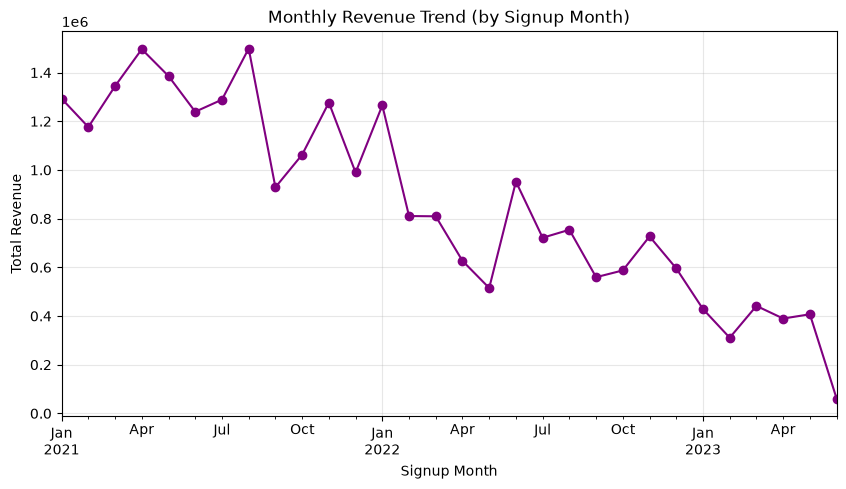

In [45]:
# Monthly revenue trend (line chart)
monthly_rev = df.groupby(df["signup_date"].dt.to_period("M"))["total_revenue"].sum()

plt.figure(figsize=(10, 5))
monthly_rev.plot(kind="line", marker="o", color="purple")
plt.title("Monthly Revenue Trend (by Signup Month)")
plt.xlabel("Signup Month")
plt.ylabel("Total Revenue")
plt.grid(alpha=0.3)
plt.savefig("charts/12_monthly_revenue_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** revenue is lower for recent signups because newer customers have had less time to build up revenue. This reflects tenure rather than true seasonality. The data has no payment dates, so revenue is grouped by signup month.

### Modeling support: correlation

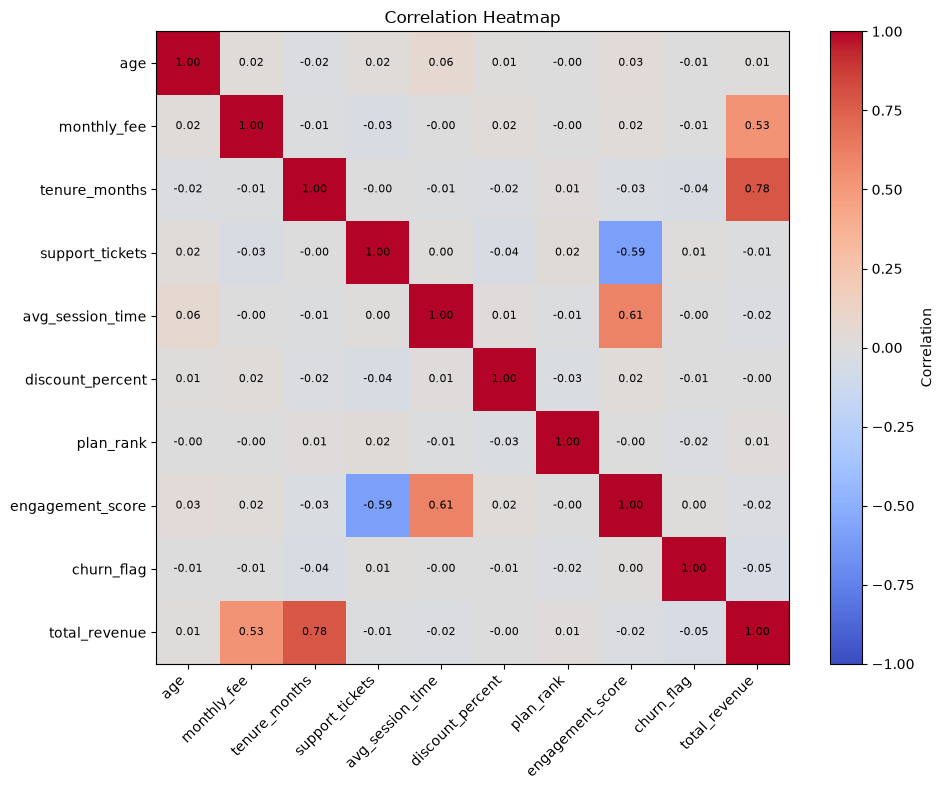

In [46]:
# Correlation heatmap
num_cols = ["age", "monthly_fee", "tenure_months", "support_tickets",
            "avg_session_time", "discount_percent", "plan_rank",
            "engagement_score", "churn_flag", "total_revenue"]

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)

# Write the number inside each square
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("charts/13_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** only `tenure_months` (0.78) and `monthly_fee` (0.53) are strongly related to `total_revenue`. All other features are close to 0.

## 6. Linear Regression Model
Predicting `total_revenue` from tenure, fee, discount, plan, age, support tickets, session time, engagement and churn. `revenue_per_month` is excluded because it is calculated from the target and would leak the answer.

In [47]:
# Linear Regression model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Features (X) and target (y)
features = ["tenure_months", "monthly_fee", "discount_percent", "plan_rank",
            "age", "support_tickets", "avg_session_time",
            "engagement_score", "churn_flag"]
X = df[features]
y = df["total_revenue"]

# 80% to train, 20% to test; random_state makes the split repeatable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)          # learn from the training data
y_pred = model.predict(X_test)       # predict revenue for unseen customers

print("R2   :", round(r2_score(y_test, y_pred), 4))
print("MAE  :", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))

# Coefficients: the effect of each feature on revenue
print(pd.Series(model.coef_, index=features).round(2))

R2   : 0.9187
MAE  : 2557.0
RMSE : 3421.33
tenure_months       879.89
monthly_fee          17.36
discount_percent     -5.65
plan_rank            75.17
age                   6.32
support_tickets      -8.96
avg_session_time     -1.05
engagement_score     -5.75
churn_flag         -288.46
dtype: float64


**Result:** R² = 0.9187, MAE = 2,557, RMSE = 3,421. The model explains about 92% of the variation in revenue. `tenure_months` is the main driver (about +880 per extra month), and churned customers earn about 288 less. Discount, age, support tickets, session time and engagement score have almost no effect.

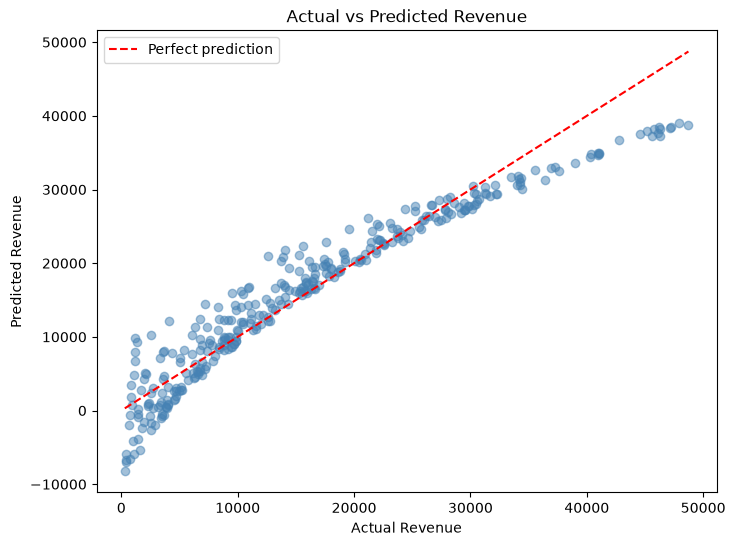

In [48]:
# Actual vs predicted revenue (chart 14)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="steelblue")

# Perfect-prediction line: points on it are predicted exactly
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.legend()
plt.savefig("charts/14_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** the points sit close to the red line, so predictions are accurate overall.

## 7. Conclusions and Recommendations

**Key findings**
1. Tenure is the main revenue driver. Longer-staying customers are worth much more.
2. Engagement score, session time, support tickets and age show almost no relationship with revenue.
3. Discounts had no effect on total revenue in this data.
4. Basic brings the most total revenue because it has the most customers. Standard has the lowest churn (19.4%).
5. Email is the best acquisition channel; Ads is the weakest.
6. Linear Regression predicts revenue well (R² about 0.92).

**Recommendations**
- Focus on retention, since each extra month a customer stays adds about 880 in revenue.
- Investigate why Basic and Premium customers churn more than Standard.
- Shift marketing budget from Ads towards Email, Organic and Referral.
- Review discounting, as it does not increase revenue here.

**Limitations**
- 852 records (about a third) were removed because of illogical dates.
- Revenue is almost exactly `monthly_fee × tenure_months`, so the model mostly learns that relationship.
- The monthly revenue trend uses signup month because there are no payment dates.